Every model so far has been given labels. K-means is the first that is not: it is handed
only the points and asked to find structure.

The objective is one line &mdash; put each point with the nearest centre, and place the centres
so the total squared distance is as small as possible:

$$\min_{\{S_1,\dots,S_k\}} \;\; \sum_{j=1}^{k}\sum_{\mathbf{x}\in S_j}\lVert\mathbf{x}-\boldsymbol{\mu}_j\rVert^2$$

Finding the true optimum is NP-hard, so k-means uses **Lloyd's algorithm**: alternate two
steps that each provably reduce the objective.

1. **Assign** every point to its nearest centre.
2. **Update** every centre to the mean of the points assigned to it.

Neither step can ever increase the objective, so the algorithm always converges &mdash; though
not necessarily to the best answer. Every iteration is shown below with the distances and
the means written out, and the result is checked against scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs used in the classification walkthroughs &mdash; but the labels are
**withheld**. K-means never sees them.

They are kept aside for one purpose only: at the end we can ask whether the clusters the
algorithm found happen to line up with the classes it was never told about.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

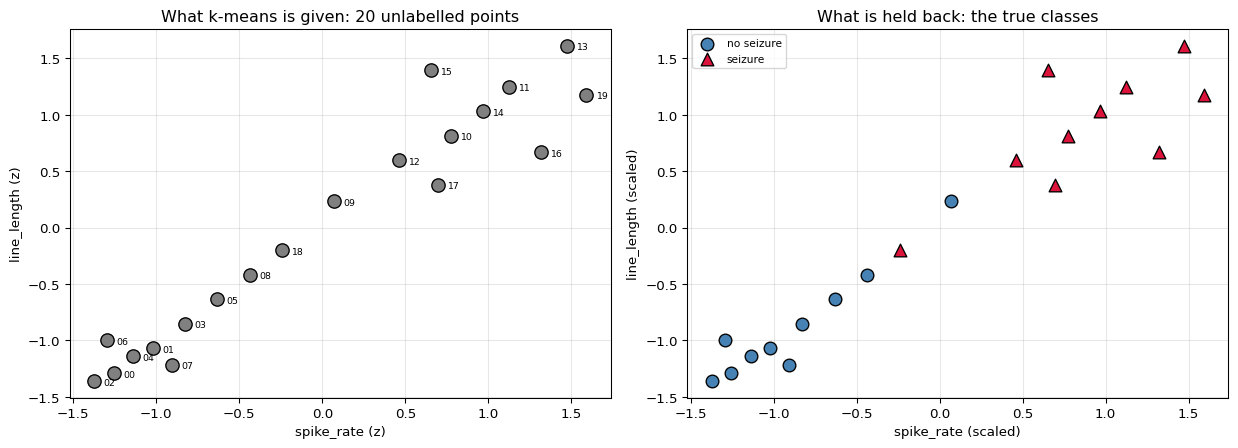

Scaling matters here for the same reason it did for KNN: k-means minimises
SQUARED EUCLIDEAN distance, so an unscaled feature with a larger range
would dominate the objective and the clusters would only reflect it.


In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(Pz[:,0], Pz[:,1], s=100, c="grey", edgecolor="k", zorder=3)
for i in range(n2):
    axes[0].annotate(ep_ids[i][2:], (Pz[i,0], Pz[i,1]), fontsize=7,
                     xytext=(7,-3), textcoords="offset points")
axes[0].set(xlabel=feat2[0]+" (z)", ylabel=feat2[1]+" (z)",
            title="What k-means is given: 20 unlabelled points")
axes[0].grid(alpha=.3)
plot2d(ax=axes[1], scaled=True, title="What is held back: the true classes")
plt.tight_layout(); plt.show()

print("Scaling matters here for the same reason it did for KNN: k-means minimises")
print("SQUARED EUCLIDEAN distance, so an unscaled feature with a larger range")
print("would dominate the objective and the clusters would only reflect it.")

---
# 2. Initialisation

Lloyd's algorithm needs somewhere to start, and the starting point matters: the objective
is non-convex, so different initialisations can converge to different answers.

**Random init** picks $k$ points at random. **k-means++** spreads them out: the first
centre is random, and each subsequent one is drawn with probability proportional to
$D(\mathbf{x})^2$, the squared distance to the nearest centre already chosen. Far-away
points are far more likely to be picked, which avoids starting with two centres on top
of each other.

In [4]:
K = 2
rng = np.random.default_rng(3)

def kmeanspp(A, k, rng):
    idx = [int(rng.integers(len(A)))]
    print(f"   centre 1: chosen uniformly at random -> {ep_ids[idx[0]]}")
    for c in range(1, k):
        d2 = np.min(((A[:, None, :] - A[idx][None, :, :])**2).sum(axis=2), axis=1)
        prob = d2 / d2.sum()
        nxt = int(rng.choice(len(A), p=prob))
        print(f"   centre {c+1}: sampled with P proportional to D(x)^2")
        top = np.argsort(-prob)[:4]
        for i in top:
            mark = "  <- picked" if i == nxt else ""
            print(f"        {ep_ids[i]}: D^2 = {d2[i]:7.4f}, P = {prob[i]:6.4f}{mark}")
        idx.append(nxt)
    return A[idx].copy(), idx

print("k-means++ initialisation:\n")
init_c, init_idx = kmeanspp(Pz, K, rng)
print(f"\nstarting centres:")
for j in range(K):
    print(f"   mu_{j} = {np.round(init_c[j], 5)}   (at {ep_ids[init_idx[j]]})")

d_between = np.sqrt(((init_c[0]-init_c[1])**2).sum())
print(f"\ndistance between them: {d_between:.4f}")
rand_c = Pz[rng.choice(n2, K, replace=False)]
print(f"a purely random pair would often be much closer, e.g. "
      f"{np.sqrt(((rand_c[0]-rand_c[1])**2).sum()):.4f}")

k-means++ initialisation:

   centre 1: chosen uniformly at random -> ep16
   centre 2: sampled with P proportional to D(x)^2
        ep02: D^2 = 11.3638, P = 0.1357  <- picked
        ep00: D^2 = 10.4586, P = 0.1249
        ep06: D^2 =  9.6099, P = 0.1147
        ep04: D^2 =  9.3232, P = 0.1113

starting centres:
   mu_0 = [1.3184 0.6706]   (at ep16)
   mu_1 = [-1.373  -1.3592]   (at ep02)

distance between them: 3.3710
a purely random pair would often be much closer, e.g. 0.2921


---
# 3. Lloyd's Algorithm, Iteration by Iteration

$$\text{assign: } \; c_i = \arg\min_j \lVert\mathbf{x}_i - \boldsymbol{\mu}_j\rVert^2
\qquad\qquad
\text{update: } \; \boldsymbol{\mu}_j = \frac{1}{|S_j|}\sum_{i \in S_j}\mathbf{x}_i$$

The **inertia** (the objective being minimised) is printed after each step so the
monotone decrease is visible:

$$\text{inertia} = \sum_i \lVert\mathbf{x}_i - \boldsymbol{\mu}_{c_i}\rVert^2$$

In [5]:
def assign(A, cen):
    d2 = ((A[:, None, :] - cen[None, :, :])**2).sum(axis=2)
    return d2.argmin(axis=1), d2

def inertia(A, cen, lab):
    return float(((A - cen[lab])**2).sum())

cen = init_c.copy()
history = [cen.copy()]
labels_hist = []

for it in range(1, 7):
    lab, d2 = assign(Pz, cen)
    inert_after_assign = inertia(Pz, cen, lab)
    labels_hist.append(lab.copy())

    print(f"=========== ITERATION {it} ===========")
    print(f"centres now: mu_0 = {np.round(cen[0],5)},  mu_1 = {np.round(cen[1],5)}\n")
    print(f"ASSIGN - squared distance to each centre\n")
    print(f"{'id':>6}  {'d^2 to mu_0':>13}  {'d^2 to mu_1':>13}  {'nearest':>8}")
    print("-" * 48)
    for i in range(n2):
        star0 = " *" if lab[i] == 0 else "  "
        star1 = " *" if lab[i] == 1 else "  "
        print(f"{ep_ids[i]:>6}  {d2[i,0]:>11.5f}{star0}  {d2[i,1]:>11.5f}{star1}  "
              f"{lab[i]:>8}")
    print("-" * 48)
    print(f"cluster sizes: {np.bincount(lab, minlength=K).tolist()}")
    print(f"inertia after assignment: {inert_after_assign:.6f}\n")

    new_cen = np.array([Pz[lab == j].mean(axis=0) if (lab == j).any() else cen[j]
                        for j in range(K)])
    print(f"UPDATE - each centre becomes the mean of its members\n")
    for j in range(K):
        mem = np.where(lab == j)[0]
        print(f"   cluster {j} ({len(mem)} points): {[ep_ids[i] for i in mem]}")
        for dcol in range(2):
            vals = " + ".join(f"{Pz[i,dcol]:+.3f}" for i in mem[:6])
            more = " + ..." if len(mem) > 6 else ""
            print(f"      {feat2[dcol]}: ({vals}{more}) / {len(mem)} = "
                  f"{new_cen[j,dcol]:+.6f}")
        print(f"      mu_{j} : {np.round(cen[j],5)}  ->  {np.round(new_cen[j],5)}")
    shift = np.sqrt(((new_cen - cen)**2).sum(axis=1))
    print(f"\n   centre movement: {np.round(shift, 8)}")
    inert_after_update = inertia(Pz, new_cen, lab)
    print(f"   inertia after update: {inert_after_update:.6f}  "
          f"(was {inert_after_assign:.6f})")

    cen = new_cen
    history.append(cen.copy())
    if shift.max() < 1e-10:
        print(f"\n>>> centres stopped moving - CONVERGED after {it} iterations\n")
        break
    print()

final_lab, _ = assign(Pz, cen)
final_inertia = inertia(Pz, cen, final_lab)
print(f"final inertia: {final_inertia:.6f}")

=========== ITERATION 1 ===========
centres now: mu_0 = [1.3184 0.6706],  mu_1 = [-1.373  -1.3592]

ASSIGN - squared distance to each centre

    id    d^2 to mu_0    d^2 to mu_1   nearest
------------------------------------------------
  ep00     10.45856        0.01895 *         1
  ep01      8.50428        0.20732 *         1
  ep02     11.36379        0.00000 *         1
  ep03      6.91999        0.55571 *         1
  ep04      9.32321        0.10207 *         1
  ep05      5.50636        1.07477 *         1
  ep06      9.60987        0.13747 *         1
  ep07      8.49577        0.24011 *         1
  ep08      4.26339        1.76450 *         1
  ep09      1.74717 *      4.62641           0
  ep10      0.31923 *      9.33213           0
  ep11      0.37437 *     13.04268           0
  ep12      0.74165 *      7.19197           0
  ep13      0.91247 *     16.94190           0
  ep14      0.25462 *     11.20020           0
  ep15      0.96522 *     11.70257           0
  ep16    

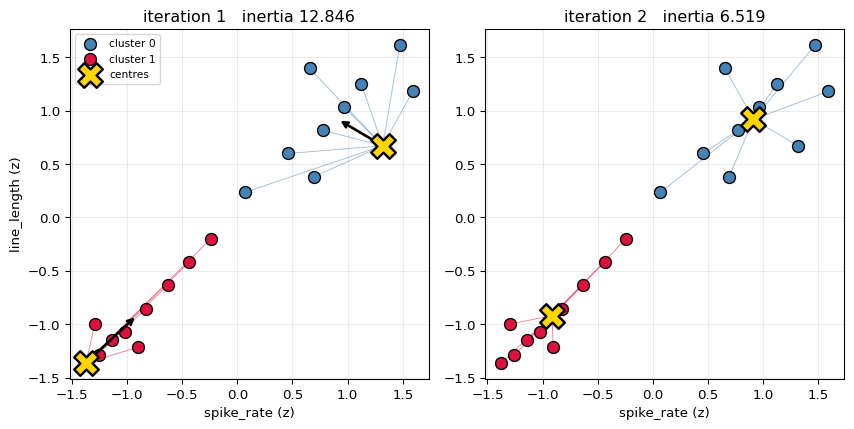

Black arrows show where each centre moves next. The thin lines are the
assignments whose squared lengths are being summed into the inertia.


In [6]:
steps = min(len(history) - 1, 4)
fig, axes = plt.subplots(1, steps, figsize=(4.5*steps, 4.6))
if steps == 1:
    axes = [axes]
for s, ax in enumerate(axes):
    cprev = history[s]
    lab_s, _ = assign(Pz, cprev)
    for j, col in enumerate(["steelblue", "crimson"]):
        m = lab_s == j
        ax.scatter(Pz[m,0], Pz[m,1], c=col, s=80, edgecolor="k", zorder=3,
                   label=f"cluster {j}")
        for i in np.where(m)[0]:
            ax.plot([Pz[i,0], cprev[j,0]], [Pz[i,1], cprev[j,1]],
                    color=col, lw=.7, alpha=.5, zorder=2)
    ax.scatter(cprev[:,0], cprev[:,1], marker="X", s=340, c="gold",
               edgecolor="k", linewidths=1.8, zorder=5, label="centres")
    if s + 1 < len(history):
        nxt = history[s+1]
        for j in range(K):
            ax.annotate("", xy=nxt[j], xytext=cprev[j],
                        arrowprops=dict(arrowstyle="->", lw=2, color="k"))
    ax.set(title=f"iteration {s+1}   inertia {inertia(Pz, cprev, lab_s):.3f}",
           xlabel=feat2[0]+" (z)")
    if s == 0:
        ax.set_ylabel(feat2[1]+" (z)"); ax.legend(fontsize=8)
    ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

print("Black arrows show where each centre moves next. The thin lines are the")
print("assignments whose squared lengths are being summed into the inertia.")

### Why it always converges

Each step is a minimisation of the *same* objective over a different variable:

* **Assign** holds the centres fixed and picks the best cluster for each point &mdash; by
  construction it cannot increase the total.
* **Update** holds the assignment fixed and picks the best centre for each cluster. The
  mean is exactly the minimiser of $\sum_{i\in S}\lVert\mathbf{x}_i-\boldsymbol{\mu}\rVert^2$,
  since $\frac{d}{d\mu}\sum(x_i-\mu)^2 = -2\sum(x_i-\mu) = 0 \Rightarrow \mu = \bar{x}$.

So the inertia is non-increasing and bounded below by zero. There are finitely many
possible assignments, so it must stop.

What that argument does **not** promise is a good answer &mdash; only a stable one.

In [7]:
print("inertia after every half-step (never increases)\n")
cen_t = init_c.copy()
seq = []
for it in range(8):
    lab_t, _ = assign(Pz, cen_t)
    seq.append(("assign", inertia(Pz, cen_t, lab_t)))
    new_t = np.array([Pz[lab_t == j].mean(axis=0) if (lab_t == j).any() else cen_t[j]
                      for j in range(K)])
    seq.append(("update", inertia(Pz, new_t, lab_t)))
    if np.abs(new_t - cen_t).max() < 1e-12:
        cen_t = new_t
        break
    cen_t = new_t

print(f"{'step':>5}  {'kind':>8}  {'inertia':>12}  {'change':>12}")
print("-" * 44)
prev = None
mono = True
for k, (kind, v) in enumerate(seq):
    ch = "" if prev is None else f"{v - prev:+.6f}"
    if prev is not None and v > prev + 1e-12:
        mono = False
    print(f"{k:>5}  {kind:>8}  {v:>12.6f}  {ch:>12}")
    prev = v
print("-" * 44)
print(f"\nmonotonically non-increasing throughout? {mono}")

print(f"\n\nverifying that the MEAN is the optimal centre for cluster 0:\n")
mem = np.where(final_lab == 0)[0]
true_mu = Pz[mem].mean(axis=0)
print(f"   mean of the {len(mem)} members = {np.round(true_mu, 6)}")
print(f"   sum of squared distances     = {((Pz[mem]-true_mu)**2).sum():.8f}")
rng_c = np.random.default_rng(0)
worse = 0
for _ in range(5000):
    cand = true_mu + rng_c.normal(scale=.15, size=2)
    if ((Pz[mem]-cand)**2).sum() < ((Pz[mem]-true_mu)**2).sum() - 1e-12:
        worse += 1
print(f"   random nearby centres that do better: {worse}/5000")

inertia after every half-step (never increases)

 step      kind       inertia        change
--------------------------------------------
    0    assign     12.846152              
    1    update      6.519077     -6.327076
    2    assign      6.519077     +0.000000
    3    update      6.519077     +0.000000
--------------------------------------------

monotonically non-increasing throughout? True


verifying that the MEAN is the optimal centre for cluster 0:

   mean of the 10 members = [0.9127 0.917 ]
   sum of squared distances     = 3.86724640
   random nearby centres that do better: 0/5000


---
# 4. Local Minima

The objective is non-convex, so where you start decides where you land. Running Lloyd's
algorithm from many random initialisations and keeping the best is not a refinement &mdash; it
is a necessity, and it is what `n_init` does in scikit-learn.

In [8]:
def lloyd(A, k, cen0, iters=100):
    cen_ = cen0.copy()
    for _ in range(iters):
        lab_, _ = assign(A, cen_)
        new_ = np.array([A[lab_ == j].mean(axis=0) if (lab_ == j).any() else cen_[j]
                         for j in range(k)])
        if np.abs(new_ - cen_).max() < 1e-12:
            break
        cen_ = new_
    lab_, _ = assign(A, cen_)
    return cen_, lab_, inertia(A, cen_, lab_)

rng_m = np.random.default_rng(7)
results = []
for trial in range(200):
    c0 = Pz[rng_m.choice(n2, K, replace=False)]
    _, lb, inr = lloyd(Pz, K, c0)
    results.append(round(inr, 6))

uniq = sorted(set(results))
print(f"200 random restarts, k = {K}\n")
print(f"{'inertia reached':>17}  {'times':>7}  {'share':>8}")
print("-" * 36)
for u in uniq:
    cnt = results.count(u)
    print(f"{u:>17.6f}  {cnt:>7}  {cnt/len(results):>7.1%}")
print("-" * 36)
print(f"\ndistinct local minima found: {len(uniq)}")
print(f"best: {min(uniq):.6f}   worst: {max(uniq):.6f}")
if len(uniq) > 1:
    print(f"the worst is {max(uniq)/min(uniq):.2f}x the best - starting badly costs real")
    print(f"quality, which is exactly why n_init defaults above 1 in sklearn.")
else:
    print("on this small, well-separated data every restart found the same optimum;")
    print("with more clusters or messier data that stops being true - see k = 4 below.")

for kk in (3, 4, 5):
    res = []
    for _ in range(200):
        c0 = Pz[rng_m.choice(n2, kk, replace=False)]
        _, _, inr = lloyd(Pz, kk, c0)
        res.append(round(inr, 4))
    u = sorted(set(res))
    print(f"\nk = {kk}: {len(u)} distinct optima, best {min(u):.4f}, worst {max(u):.4f}"
          f"  (best found {res.count(min(u))/len(res):.0%} of the time)")

200 random restarts, k = 2

  inertia reached    times     share
------------------------------------
         6.519077      200   100.0%
------------------------------------

distinct local minima found: 1
best: 6.519077   worst: 6.519077
on this small, well-separated data every restart found the same optimum;
with more clusters or messier data that stops being true - see k = 4 below.

k = 3: 6 distinct optima, best 3.6837, worst 4.7236  (best found 43% of the time)

k = 4: 46 distinct optima, best 2.2182, worst 4.3499  (best found 2% of the time)

k = 5: 109 distinct optima, best 1.6162, worst 3.5825  (best found 2% of the time)


---
# 5. Choosing $k$

Inertia always falls as $k$ rises &mdash; at $k = n$ it reaches zero, with every point its own
cluster. So it cannot be minimised to choose $k$.

Two standard alternatives:

**The elbow.** Plot inertia against $k$ and look for the bend where extra clusters stop
buying much. It is a judgement call, not a criterion.

**Silhouette.** For each point compare $a$, its mean distance to its own cluster, with
$b$, the mean distance to the nearest *other* cluster:

$$s = \frac{b - a}{\max(a, b)} \;\in\; [-1, 1]$$

Near $+1$ the point is comfortably inside its cluster; near $0$ it sits on a border;
negative means it would be happier elsewhere.

   k     inertia       drop   silhouette
----------------------------------------
   2      6.5191                  0.6868
   3      3.6837     2.8354       0.5733
   4      2.2182     1.4655       0.4767
   5      1.6162     0.6020       0.4410
   6      1.3230     0.2931       0.4060
   7      0.9921     0.3310       0.3757
   8      0.7635     0.2286       0.3467
----------------------------------------

best silhouette at k = 2 (0.6868)


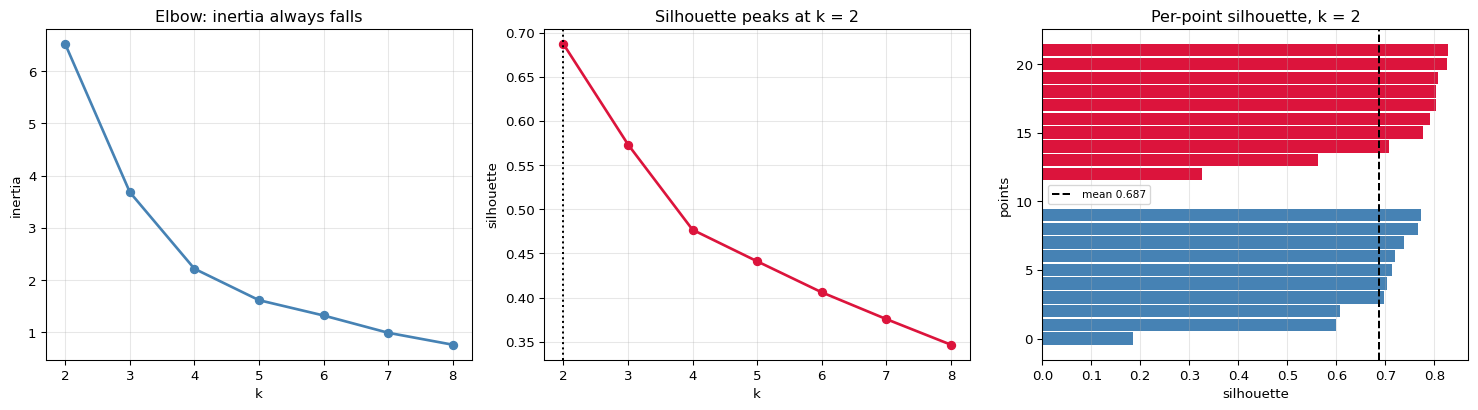


lowest silhouettes at k = 2 (the border cases):
   ep09: s = +0.1858  (cluster 0, true class 0)
   ep18: s = +0.3259  (cluster 1, true class 1)
   ep08: s = +0.5625  (cluster 1, true class 0)
   ep17: s = +0.6003  (cluster 0, true class 1)


In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

ks = range(2, 9)
inr, sil = [], []
print(f"{'k':>4}  {'inertia':>10}  {'drop':>9}  {'silhouette':>11}")
print("-" * 40)
prev = None
for k in ks:
    m = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Pz)
    s = silhouette_score(Pz, m.labels_)
    inr.append(m.inertia_); sil.append(s)
    d = "" if prev is None else f"{prev - m.inertia_:>9.4f}"
    print(f"{k:>4}  {m.inertia_:>10.4f}  {d:>9}  {s:>11.4f}")
    prev = m.inertia_
print("-" * 40)
best_k = list(ks)[int(np.argmax(sil))]
print(f"\nbest silhouette at k = {best_k} ({max(sil):.4f})")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
axes[0].plot(list(ks), inr, "o-", lw=2, color="steelblue")
axes[0].set(xlabel="k", ylabel="inertia", title="Elbow: inertia always falls")
axes[0].grid(alpha=.3)
axes[1].plot(list(ks), sil, "o-", lw=2, color="crimson")
axes[1].axvline(best_k, ls=":", color="k")
axes[1].set(xlabel="k", ylabel="silhouette", title=f"Silhouette peaks at k = {best_k}")
axes[1].grid(alpha=.3)

m2 = KMeans(n_clusters=2, n_init=20, random_state=0).fit(Pz)
sv = silhouette_samples(Pz, m2.labels_)
ypos = 0
for j, col in enumerate(["steelblue", "crimson"]):
    vals = np.sort(sv[m2.labels_ == j])
    axes[2].barh(np.arange(ypos, ypos+len(vals)), vals, color=col, height=.9)
    ypos += len(vals) + 2
axes[2].axvline(sv.mean(), ls="--", color="k", label=f"mean {sv.mean():.3f}")
axes[2].set(xlabel="silhouette", ylabel="points", title="Per-point silhouette, k = 2")
axes[2].legend(fontsize=8); axes[2].grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

print(f"\nlowest silhouettes at k = 2 (the border cases):")
for i in np.argsort(sv)[:4]:
    print(f"   {ep_ids[i]}: s = {sv[i]:+.4f}  (cluster {m2.labels_[i]}, "
          f"true class {t2[i]})")

---
# 6. Did the Clusters Find the Classes?

K-means never saw a label, so cluster *0* has no reason to correspond to class *0* &mdash; the
numbering is arbitrary. The comparison has to be made up to a permutation of labels, and
the standard tool is the **adjusted Rand index**, which is 0 for random agreement and 1
for a perfect match.

In [10]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix

km = KMeans(n_clusters=2, n_init=20, random_state=0).fit(Pz)
cm = confusion_matrix(t2, km.labels_)

print("cross-tabulation: true class vs discovered cluster\n")
print(f"{'':>14}  {'cluster 0':>10}  {'cluster 1':>10}")
print("-" * 40)
for c in range(2):
    print(f"{cls_names[c]:>14}  {cm[c,0]:>10}  {cm[c,1]:>10}")
print("-" * 40)

acc_direct = (km.labels_ == t2).mean()
acc_flip = (1 - km.labels_ == t2).mean()
print(f"\nagreement as-is        : {acc_direct:.4f}")
print(f"agreement with labels flipped: {acc_flip:.4f}")
print(f"best alignment         : {max(acc_direct, acc_flip):.4f}")
print(f"adjusted Rand index    : {adjusted_rand_score(t2, km.labels_):.4f}")

mism = np.where((km.labels_ if acc_direct >= acc_flip else 1-km.labels_) != t2)[0]
print(f"\ndisagreeing epochs: {[ep_ids[i] for i in mism]}")
print(f"those are the two planted overlaps - the same points logistic regression")
print(f"and the SVM could not place either. Unsupervised or not, they sit in the")
print(f"wrong neighbourhood.")

cross-tabulation: true class vs discovered cluster

                 cluster 0   cluster 1
----------------------------------------
    no seizure           1           9
       seizure           9           1
----------------------------------------

agreement as-is        : 0.1000
agreement with labels flipped: 0.9000
best alignment         : 0.9000
adjusted Rand index    : 0.6200

disagreeing epochs: ['ep09', 'ep18']
those are the two planted overlaps - the same points logistic regression
and the SVM could not place either. Unsupervised or not, they sit in the
wrong neighbourhood.


### What k-means cannot do

The objective assumes clusters are **round, similarly sized, and separated by distance**.
When that is false, the algorithm still returns an answer &mdash; a confidently wrong one.

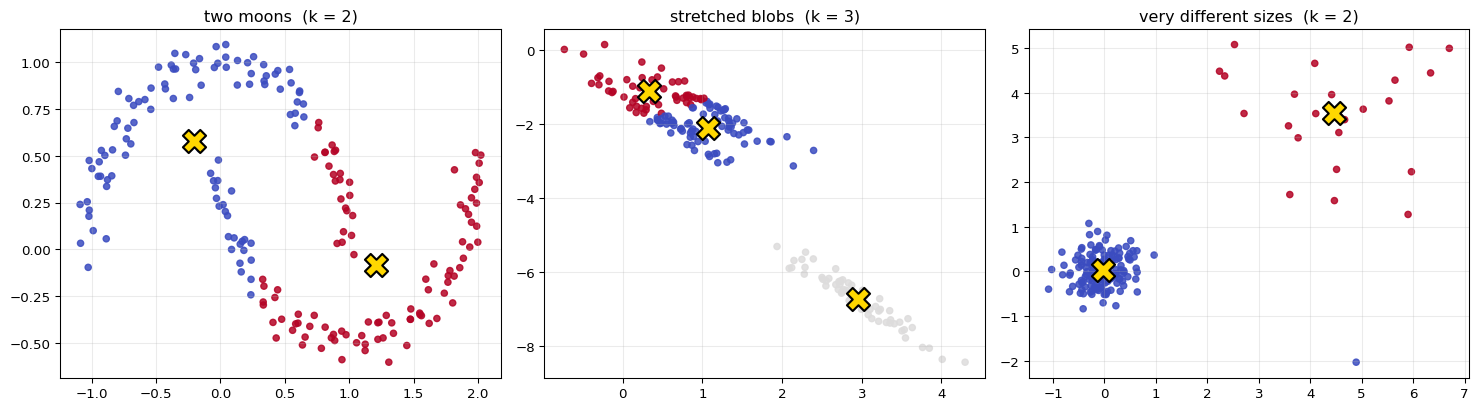

Left   : the moons are separated by SHAPE, not by distance to a centre.
Middle : stretched clusters get sliced across, because the objective is
         isotropic - it has no notion of a direction.
Right  : the large sparse cluster gets carved up to balance squared error.

All three failures come from the same source: minimising squared distance
to a single point per cluster can only ever produce convex, roughly
spherical regions. Density methods (DBSCAN) and Gaussian mixtures with
full covariance handle these; k-means structurally cannot.


In [11]:
from sklearn.datasets import make_moons, make_blobs

rngd = np.random.default_rng(0)
moons, _ = make_moons(n_samples=200, noise=.06, random_state=0)
aniso_base, _ = make_blobs(n_samples=200, centers=3, random_state=2, cluster_std=.6)
aniso = aniso_base @ np.array([[0.6, -0.6], [-0.4, 0.8]])
uneven = np.vstack([rngd.normal(0, .35, (150, 2)),
                    rngd.normal(4, 1.6, (25, 2))])

cases = [("two moons", moons, 2), ("stretched blobs", aniso, 3),
         ("very different sizes", uneven, 2)]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))
for ax, (name, A, k) in zip(axes, cases):
    m = KMeans(n_clusters=k, n_init=20, random_state=0).fit(A)
    ax.scatter(A[:,0], A[:,1], c=m.labels_, cmap="coolwarm", s=22, alpha=.85)
    ax.scatter(m.cluster_centers_[:,0], m.cluster_centers_[:,1], marker="X",
               s=300, c="gold", edgecolor="k", linewidths=1.6, zorder=5)
    ax.set(title=f"{name}  (k = {k})"); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

print("Left   : the moons are separated by SHAPE, not by distance to a centre.")
print("Middle : stretched clusters get sliced across, because the objective is")
print("         isotropic - it has no notion of a direction.")
print("Right  : the large sparse cluster gets carved up to balance squared error.")
print()
print("All three failures come from the same source: minimising squared distance")
print("to a single point per cluster can only ever produce convex, roughly")
print("spherical regions. Density methods (DBSCAN) and Gaussian mixtures with")
print("full covariance handle these; k-means structurally cannot.")

---
# 7. Checking Against scikit-learn

In [12]:
sk = KMeans(n_clusters=K, n_init=50, random_state=0).fit(Pz)

best_c, best_l, best_i = None, None, np.inf
rng_f = np.random.default_rng(0)
for _ in range(200):
    c0 = Pz[rng_f.choice(n2, K, replace=False)]
    c_, l_, i_ = lloyd(Pz, K, c0)
    if i_ < best_i:
        best_c, best_l, best_i = c_, l_, i_

print(f"our best over 200 restarts : inertia {best_i:.8f}")
print(f"sklearn (n_init=50)        : inertia {sk.inertia_:.8f}")
print(f"MATCH: {np.isclose(best_i, sk.inertia_, atol=1e-8)}\n")

order_ours = np.argsort(best_c[:, 0])
order_sk = np.argsort(sk.cluster_centers_[:, 0])
print("centres (sorted so the arbitrary numbering lines up):")
for a, b in zip(order_ours, order_sk):
    print(f"   ours {np.round(best_c[a], 8)}   sklearn {np.round(sk.cluster_centers_[b], 8)}")
print(f"\ncentres MATCH: "
      f"{np.allclose(best_c[order_ours], sk.cluster_centers_[order_sk], atol=1e-8)}")

remap = {int(a): int(b) for a, b in zip(order_ours, order_sk)}
ours_mapped = np.array([remap[int(v)] for v in best_l])
print(f"assignments MATCH (up to relabelling): "
      f"{np.array_equal(ours_mapped, sk.labels_)}")

print(f"\ninertia recomputed from scratch: "
      f"{float(((Pz - sk.cluster_centers_[sk.labels_])**2).sum()):.8f}")
print(f"sklearn's reported inertia_    : {sk.inertia_:.8f}")
print(f"MATCH: {np.isclose(((Pz - sk.cluster_centers_[sk.labels_])**2).sum(), sk.inertia_)}")

our best over 200 restarts : inertia 6.51907675
sklearn (n_init=50)        : inertia 6.51907675
MATCH: True

centres (sorted so the arbitrary numbering lines up):
   ours [-0.9127 -0.917 ]   sklearn [-0.9127 -0.917 ]
   ours [0.9127 0.917 ]   sklearn [0.9127 0.917 ]

centres MATCH: True
assignments MATCH (up to relabelling): True

inertia recomputed from scratch: 6.51907675
sklearn's reported inertia_    : 6.51907675
MATCH: True


---
# 8. Summary

| Stage | Formula |
|---|---|
| Objective | $\sum_j\sum_{\mathbf{x}\in S_j}\lVert\mathbf{x}-\boldsymbol{\mu}_j\rVert^2$ |
| Assign | $c_i = \arg\min_j\lVert\mathbf{x}_i-\boldsymbol{\mu}_j\rVert^2$ |
| Update | $\boldsymbol{\mu}_j = \frac{1}{\lvert S_j\rvert}\sum_{i\in S_j}\mathbf{x}_i$ |
| Cost | $O(n\,k\,d)$ per iteration |
| Convergence | guaranteed &mdash; to a **local** optimum |
| Choosing $k$ | elbow, silhouette; never inertia alone |

**The one idea:** alternate between two steps that each minimise the same objective over
one variable while holding the other fixed. Neither can make things worse, so the process
must settle. That pattern &mdash; coordinate descent &mdash; recurs well beyond k-means; the EM
algorithm for Gaussian mixtures is the same skeleton with soft assignments.

**Its honest limits:** you must choose $k$ in advance; the answer depends on
initialisation; and clusters can only ever be round blobs of similar size, because a
single mean per cluster cannot express anything else.

**What is deliberately left out:** k-medoids and k-medians, mini-batch k-means for large
data, Gaussian mixture models (soft assignment plus covariance), DBSCAN and hierarchical
clustering, and the formal proof of the $O(\log k)$ approximation guarantee that
k-means++ provides.